# 02 · Metadata table, analysis scope and quality control

**Why a scope is needed.** Growth rate changes for different reasons – nutrient quality, temperature, osmotic stress, antibiotics, stationary phase – and the proteome answers each differently. Pooling them would make "the growth-rate effect" an average of unrelated responses. The primary analysis is therefore restricted to **nutrient-quality conditions**: batch culture, 37 °C, growth rate set only by the medium.

**How the scope is applied.** Every sample receives a `Perturbation_Type` and the rule that assigned it (`Scope_Rule`). Rules are regular expressions in `config.yml`; manual decisions go in `metadata/scope_overrides.tsv` with a written reason. The classification uses metadata only – never protein abundances – so it cannot leak information into later models.

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


In [2]:
X, obs, var = ingest.load_processed(cfg)
obs = scope.classify(obs, cfg)

summary = pd.crosstab(obs["Dataset_Source"], obs["Perturbation_Type"]).reindex(obs["Dataset_Source"].unique())
display(summary)

Perturbation_Type,anaerobic,nutrient_quality,osmotic,other_perturbation,oxidative,stationary,temperature
Dataset_Source,,,,,,,
schmidt_2016,0,2,0,0,0,0,0
mori_2021,1,9,3,2,1,2,1
wu_2023,0,21,0,0,0,0,0
zhu_2025,0,7,0,0,0,0,5


## 1 · Review every decision

The rules are conservative keyword matches. **Read this table once against the papers**, especially for Mori 2021, whose conditions are described in free text. If a sample is misclassified, add one line to `metadata/scope_overrides.tsv` (`Sample_ID`, `Perturbation_Type`, `Reason`) and re-run – do not edit the table by hand.

In [3]:
decision_columns = ["Condition_ID", "Base_Medium", "Carbon_Source", "Temperature_C", "Special_Procedure",
                    GROWTH, "Perturbation_Type", "Scope_Rule", "In_Scope"]
with pd.option_context("display.max_rows", 200):
    display(obs[decision_columns])

,Condition_ID,Base_Medium,Carbon_Source,Temperature_C,Special_Procedure,Specific_Growth_Rate_h-1,Perturbation_Type,Scope_Rule,In_Scope
Sample_ID,,,,,,,,,
schmidt_2016:LB,LB,LB,Undefined (complex),37.0,NaN,2.300000,nutrient_quality,no perturbation rule matched,True
schmidt_2016:Glucose,Glucose_Minimal,Minimal,Glucose,37.0,NaN,1.030000,nutrient_quality,no perturbation rule matched,True
mori_2021:Lib-01,Hi Temp,MOPS (Record's),0.2% glucose,NaN,"High temperature, 42 °C",0.884869,temperature,description matches /\btemp/,False
mori_2021:Lib-02,Hi Osm 1,MOPS (Record's),0.2% glucose,NaN,Seed culture: LB with 0.3M NaCl,0.244640,osmotic,description matches /\bosm/,False
mori_2021:Lib-03,Hi Osm 2,MOPS (Record's),0.2% fructose,NaN,Seed culture: LB with 0.3M NaCl,0.378080,osmotic,description matches /\bosm/,False
mori_2021:Lib-04,Hi Osm 3,MOPS (Record's),0.2% sorbitol,NaN,Seed culture: LB with 0.3M NaCl,0.378080,osmotic,description matches /\bosm/,False
mori_2021:Lib-05,Anaerobic,Special N-C- (see Methods),10 mM glucose,NaN,Grown anaerobically,0.681784,anaerobic,description matches /anaerob/,False
mori_2021:Lib-06,Acetate,Phosphate buffered N-C- medium,0.4% sodium acetate,NaN,NaN,0.501070,nutrient_quality,no perturbation rule matched,True
mori_2021:Lib-07,Kanamycin,Phosphate buffered N-C- medium,0.4% glucose,NaN,NaN,0.742658,nutrient_quality,no perturbation rule matched,True


## 2 · Design check: can dataset and growth rate be separated?

Batch effects can mimic biology, and correction cannot recover a comparison the design does not contain. The pooled slope in notebook 03 is estimated from **within-dataset** contrasts only, so each dataset contributes in proportion to the spread of growth rates it covers. A dataset with a single in-scope condition contributes nothing to the slope; one with two conditions contributes one contrast.

,n_samples_total,n_samples,n_conditions,growth_min,growth_median,growth_max
Dataset_Source,,,,,,
schmidt_2016,2,2,2,1.030000,1.665000,2.300000
mori_2021,19,9,9,0.240398,0.770164,1.124022
wu_2023,21,21,10,0.670000,0.960000,2.190000
zhu_2025,12,7,6,0.420000,0.949000,1.900000


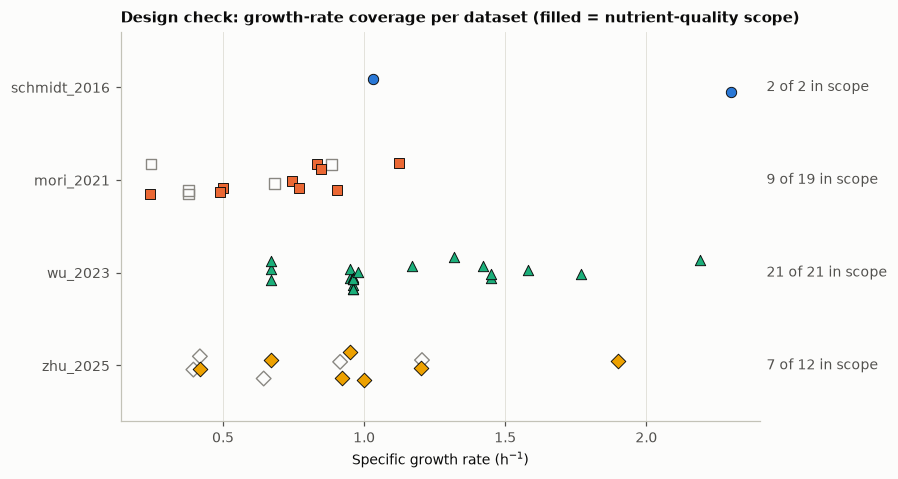

In [4]:
design = scope.design_table(obs, cfg)
display(design)
fig = plots.plot_design(obs, cfg.figures / "02_design_growth_rate_by_dataset.png")
plt.show()

A strip plot per dataset is used because the message is the **overlap of growth-rate ranges** between studies and how many samples survive the scope; filled markers are in scope, open markers are excluded.

## 3 · Replicates are not independent conditions

Several runs of the same medium are technical or biological replicates of **one** condition. They are averaged before any statistics (notebook 03), so the number of independent units is the number of conditions below, not the number of MS runs.

In [5]:
scoped = obs[obs["In_Scope"]]
replicates = (scoped.groupby(["Dataset_Source", "Condition_ID"], sort=False)
              .agg(n_runs=(GROWTH, "size"), growth_rate=(GROWTH, "mean"), MS_batches=("MS_Batch", lambda s: ", ".join(sorted(set(map(str, s))))))
              .reset_index())
display(replicates)
print(f"In scope: {len(scoped)} MS runs = {len(replicates)} independent conditions "
      f"across {scoped['Dataset_Source'].nunique()} datasets.")

,Dataset_Source,Condition_ID,n_runs,growth_rate,MS_batches
0,schmidt_2016,LB,1,2.300000,schmidt_2016
1,schmidt_2016,Glucose_Minimal,1,1.030000,schmidt_2016
2,mori_2021,Acetate,1,0.501070,mori_2021
3,mori_2021,Kanamycin,1,0.742658,mori_2021
4,mori_2021,Poor N,1,0.240398,mori_2021
5,mori_2021,Carbon 46,1,0.904105,mori_2021
6,mori_2021,Carbon 37,1,1.124022,mori_2021
7,mori_2021,Carbon 85,1,0.489280,mori_2021
8,mori_2021,Carbon 50,1,0.831777,mori_2021
9,mori_2021,Carbon 54,1,0.770164,mori_2021


In scope: 39 MS runs = 27 independent conditions across 4 datasets.


## 4 · Unit consistency between datasets

If all four datasets are on the same scale, the median log10 ratio between any two (over proteins quantified in both) is close to 0. A value around ±0.5 would be a three-fold mismatch, as happens when one dataset is expressed per dry weight and another per total protein.

In [6]:
offsets = scope.cross_dataset_offsets(X, obs)
display(offsets.round(3))

,dataset_A,dataset_B,n_shared_proteins,median_log10_ratio_A_over_B,IQR_log10_ratio,spearman_r
0,mori_2021,schmidt_2016,1885,0.276,0.751,0.777
1,mori_2021,wu_2023,1983,-0.008,0.295,0.874
2,mori_2021,zhu_2025,1739,-0.109,0.346,0.835
3,schmidt_2016,wu_2023,1808,-0.258,0.611,0.831
4,schmidt_2016,zhu_2025,1626,-0.331,0.584,0.849
5,wu_2023,zhu_2025,1712,-0.093,0.266,0.867


## 5 · Save the metadata table

`sample_metadata_scoped.tsv` is the single metadata table used by every later notebook: sample and condition identifiers, strain, medium, temperature, MS batch, growth rate **with its source**, original unit, source file, perturbation type and scope decision.

In [7]:
path = scope.save_scoped(cfg, obs)
obs[decision_columns].to_csv(cfg.tables / "02_scope_decisions.tsv", sep="\t")
design.to_csv(cfg.tables / "02_design_table.tsv", sep="\t")
replicates.to_csv(cfg.tables / "02_conditions_in_scope.tsv", sep="\t", index=False)
offsets.to_csv(cfg.tables / "02_cross_dataset_offsets.tsv", sep="\t", index=False)

config.log_run(cfg, "02_metadata_scope_qc", params={"scope": cfg["scope"]},
               inputs={"metadata/scope_overrides.tsv": config.sha256(cfg.resolve(cfg["scope"]["overrides"]))},
               outputs=[path],
               notes={"n_runs_in_scope": int(obs["In_Scope"].sum()), "n_conditions_in_scope": int(len(replicates)),
                      "perturbation_counts": obs["Perturbation_Type"].value_counts().to_dict()})
print("Written:", path.relative_to(cfg.root))

Written: data\processed\sample_metadata_scoped.tsv
